# 02_development_run.ipynb — Detach-Hydra: the decisive experiment

**Author:** Shreed

**Notebook:** `02_detach_hydra/notebooks/02_development_run.ipynb`. It follows up on the pilot in `01_pilot.ipynb`.

## The one question

> **At matched kernel budgets, does importance-ranked group pruning beat simply using a smaller Hydra?**

**What the pilot established (9 datasets × 3 seeds):**
- Group-level pruning is **exact**.
- The importance ranking beats **random** pruning.
- But it only **tied** a fresh smaller Hydra (`small_g`) at equal size (5/0/4, mean −0.21 pp).
- The automatic size-selection rule failed, mostly when the ridge alpha sat at the bottom of the authors' grid.

**How to read the outcome:**
- If Detach beats `small_g` here, it is a real contribution.
- If it does not, we write it up as an understanding result: *what* makes a small Hydra good.

**Design:**
- **Data:** the 40 "development" datasets × 5 splits (default UCR split plus 4 stratified resamples).
- **Budgets:** 4 matched kernel budgets.
- **Methods:** 6, all scored with the same scaler, the same classifier and a **wide ridge grid** `logspace(-6, 6, 25)`.
- **Statistics:** bootstrap CIs and Holm-corrected Wilcoxon tests.
- **Checks:** every equivalence check from the pilot is kept, and the notebook stops if any of them fails.

## How budgets are matched

**Group counts.** In the official `hydra.py`, `divisor = min(2, g) = 2` and `h = g // 2`.
- A model has `num_dilations × 2` **blocks** (one per dilation and input, X or diff(X)), each with `h` groups of `k = 8` kernels.
- So the total is `G = num_dilations × 2 × (g/2) = num_dilations × g` groups.
- `num_dilations` depends only on the series length, so a fresh Hydra with **g′ = 32 / 16 / 8 / 4** has exactly **50 / 25 / 12.5 / 6.25 %** of the groups of g = 64, spread evenly with **16 / 8 / 4 / 2 groups per block**.

**Methods at budget b:**

| Method | Kernels | Groups kept | Spread over blocks | What it controls for |
|---|---|---|---|---|
| `detach` | full model's | `round(b·G)`, top-ranked globally | free (may empty blocks) | the method under test |
| `detach_stratified` | full model's | `32·b` per block, top-ranked within the block | even | ranking **plus** even coverage |
| `random` | full model's | `round(b·G)` at random from all groups | free | does the ranking matter? |
| `random_stratified` | full model's | `32·b` per block at random | even | coverage alone, with the *same kernels* as detach |
| `small_g` | **fresh** `Hydra(g′)` | `32·b` per block (all of them) | even | "just use a smaller Hydra" |
| `full` | g = 64 | all | | reference (plus `full_author_grid`, using the authors' alpha grid) |

**What the comparisons separate:**
- `random_stratified` vs `random` shows the effect of **even coverage**.
- `small_g` vs `random_stratified` shows the effect of **fresh kernels** at equal coverage.
- `detach` vs `random` shows the effect of the **ranking**.

**Efficiency fact (proven bit-exact in the pilot and re-checked here).** The rebuilt `PrunedHydra` features are exactly the full features' kept columns, and `SparseScaler` is per-feature. So for **accuracy**, every pruned model built from the full model's kernels is evaluated by **column-subsetting the full features**, then refitting the scaler and the ridge. Rebuilt transforms are only needed for timing and for the equivalence assertions.

## 1. Setup

In [1]:
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"
RESULTS_DIR = ROOT / "02_detach_hydra" / "results"
FIG_DIR     = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

PROJECT_DIR = ROOT
DATA_DIR = ROOT / "data" / "ucr_tsml"          # git-ignored; aeon downloads any missing dataset here
# read only; written by 01_reproduction/notebooks/01_hydra_baseline.ipynb (run that first)
BASELINE_CSV = ROOT / "01_reproduction" / "results" / "hydra_default_baseline.csv"
print("Project directory:", PROJECT_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1


In [2]:
import importlib.util
import inspect
import json
import math
import os
import random
import sys
import traceback
import warnings
import zlib
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import wilcoxon

from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

# Ridge at small alpha with n_train << n_features gives a near-singular Gram matrix; sklearn warns and
# falls back to a least-squares solve. These are warnings, not errors - results are still computed.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")
warnings.filterwarnings("ignore", message="The least populated class")

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0


In [3]:
# ===================== configuration =====================
QUICK_RUN = False        # True: 3 datasets x 2 resamples smoke test. Set False for the full experiment.

# The 40 "development" datasets (asterisked in ROCKET, arXiv 1910.13051, Appendix D, Table 1),
# as extracted by the team. Not re-verified against the PDF in this notebook.
DEV_DATASETS = [
    "Beef", "BirdChicken", "Car", "CricketX", "CricketY", "CricketZ", "DistalPhalanxTW", "ECG5000",
    "FiftyWords", "Fish", "FordA", "FordB", "Haptics", "Herring", "InsectWingbeatSound",
    "ItalyPowerDemand", "LargeKitchenAppliances", "Lightning7", "Meat", "MedicalImages",
    "MiddlePhalanxOutlineAgeGroup", "MiddlePhalanxOutlineCorrect", "OSULeaf", "OliveOil", "Phoneme",
    "Plane", "ProximalPhalanxOutlineCorrect", "ProximalPhalanxTW", "ScreenType", "ShapeletSim",
    "Strawberry", "SwedishLeaf", "SyntheticControl", "ToeSegmentation1", "Trace",
    "UWaveGestureLibraryY", "Wafer", "WordSynonyms", "Worms", "Yoga",
]
assert len(DEV_DATASETS) == 40 and len(set(DEV_DATASETS)) == 40, "need 40 unique development datasets"

# Problem type per the UCR archive metadata (hand-entered; used only for the breakdown table)
DATASET_TYPE = {
    "Beef": "Spectro", "BirdChicken": "Image", "Car": "Sensor", "CricketX": "Motion", "CricketY": "Motion",
    "CricketZ": "Motion", "DistalPhalanxTW": "Image", "ECG5000": "ECG", "FiftyWords": "Image",
    "Fish": "Image", "FordA": "Sensor", "FordB": "Sensor", "Haptics": "Motion", "Herring": "Image",
    "InsectWingbeatSound": "Sensor", "ItalyPowerDemand": "Sensor", "LargeKitchenAppliances": "Device",
    "Lightning7": "Sensor", "Meat": "Spectro", "MedicalImages": "Image",
    "MiddlePhalanxOutlineAgeGroup": "Image", "MiddlePhalanxOutlineCorrect": "Image", "OSULeaf": "Image",
    "OliveOil": "Spectro", "Phoneme": "Sensor", "Plane": "Sensor", "ProximalPhalanxOutlineCorrect": "Image",
    "ProximalPhalanxTW": "Image", "ScreenType": "Device", "ShapeletSim": "Simulated",
    "Strawberry": "Spectro", "SwedishLeaf": "Image", "SyntheticControl": "Simulated",
    "ToeSegmentation1": "Motion", "Trace": "Sensor", "UWaveGestureLibraryY": "Motion", "Wafer": "Sensor",
    "WordSynonyms": "Image", "Worms": "Motion", "Yoga": "Image",
}
assert set(DATASET_TYPE) == set(DEV_DATASETS)

DATASETS = ["Beef", "SwedishLeaf", "Wafer"] if QUICK_RUN else DEV_DATASETS
RESAMPLES = [0, 1] if QUICK_RUN else [0, 1, 2, 3, 4]       # full-Hydra kernel seed = resample id

K = 8
G = 64                                                    # full Hydra groups (the pilot's name for g)
BUDGETS = [0.5, 0.25, 0.125, 0.0625]                      # fraction of groups kept
SMALL_G = {0.5: 32, 0.25: 16, 0.125: 8, 0.0625: 4}         # matched fresh-Hydra g'
ALPHAS = np.logspace(-6, 6, 25)                           # wide grid, used by EVERY model here
AUTHOR_ALPHAS = np.logspace(-3, 3, 10)                    # authors' grid, full model only (reference)
PRUNE_FRACTION = 0.10                                     # remove 10% of active groups per step
N_RANDOM_DRAWS = 3
N_SMALLG_SEEDS = 3
DRAW_TOL = 0.0005                                         # |delta acc| below this counts as a draw
BATCH_SIZE = 256
N_BOOT = 10_000

TIMING_DATASETS = [d for d in ["Wafer", "FordA", "Phoneme", "Yoga", "ECG5000", "SwedishLeaf"] if d in DATASETS]
TIMING_REPEATS = 3

N_THREADS = os.cpu_count()
torch.set_num_threads(N_THREADS)                          # accuracy runs: all cores

TAG = "detach_decisive_quick" if QUICK_RUN else "detach_decisive"
RUNS_CSV = RESULTS_DIR / f"{TAG}_runs.csv"
PATHS_CSV = RESULTS_DIR / f"{TAG}_paths.csv"
KEPT_CSV = RESULTS_DIR / f"{TAG}_kept_groups.csv"
TIMING_CSV = RESULTS_DIR / f"{TAG}_timing.csv"
FAIL_CSV = RESULTS_DIR / f"{TAG}_failures.csv"
FIG_PREFIX = f"{TAG}_"

CHECKS = []                                               # (check, result) log, printed in the verdict report


def log_check(name, result="PASS"):
    CHECKS.append((name, result))
    print(f"CHECK {result}: {name}")


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print(f"QUICK_RUN={QUICK_RUN} | {len(DATASETS)} datasets x {len(RESAMPLES)} resamples | threads {N_THREADS}")
print("outputs:", RUNS_CSV.name, PATHS_CSV.name, KEPT_CSV.name, TIMING_CSV.name, FAIL_CSV.name)

QUICK_RUN=False | 40 datasets x 5 resamples | threads 10
outputs: detach_decisive_runs.csv detach_decisive_paths.csv detach_decisive_kept_groups.csv detach_decisive_timing.csv detach_decisive_failures.csv DETACH_HYDRA_DECISIVE_FINDINGS.md


In [4]:
# Import the authors' Hydra BY FILE PATH (pip `hydra-core` would shadow `import hydra`). Not modified.
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)
Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

# Confirm the group arithmetic used for budget matching: divisor = 2, h = g // 2, groups = num_dilations * g
for L_ in [24, 96, 500, 1024]:
    for g_ in [64, 32, 16, 8, 4]:
        hy_ = Hydra(L_, k=K, g=g_, seed=0)
        assert hy_.divisor == 2 and hy_.h == g_ // 2
        assert hy_.W.shape == (hy_.num_dilations, 2, K * hy_.h, 1, 9)
        assert hy_.num_dilations * hy_.divisor * hy_.h == hy_.num_dilations * g_
    assert Hydra(L_, g=4, seed=0).num_dilations == Hydra(L_, g=64, seed=0).num_dilations   # same dilations
log_check("official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g")

CHECK PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g


### Verified building blocks (copied verbatim)

- **Data loader and stratified resampling:** from the earlier Positional-Hydra notebook (not included in this repository).
  - Resample 0 is the default UCR split.
  - Resamples 1–4 pool train and test, then draw the same per-class train counts with `RandomState(resample_id)`.
  - The code asserts there is no overlap and that sizes and class counts match.
- **`group_feature_index`, `kept_columns`, `PrunedHydra`** (plus helpers): from `01_pilot.ipynb`, unchanged.

In [5]:
# ---- Data loading (same checks as 01_reproduction/notebooks/01_hydra_baseline.ipynb) and stratified resampling ----
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def make_split(X_train, y_train, X_test, y_test, resample_id):
    # resample 0 = default UCR split. Otherwise pool train+test and draw a new train set with the
    # SAME per-class counts as the original train set (seeded by resample_id); the rest is the test set.
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    X = np.concatenate([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    rng = np.random.RandomState(resample_id)
    classes, counts = np.unique(y_train, return_counts=True)
    train_idx = []
    for c, n_c in zip(classes, counts):
        idx_c = np.flatnonzero(y == c)
        train_idx.append(rng.choice(idx_c, size=n_c, replace=False))
    train_idx = np.sort(np.concatenate(train_idx))
    test_idx = np.setdiff1d(np.arange(len(y)), train_idx)

    assert len(np.intersect1d(train_idx, test_idx)) == 0, "train/test overlap"
    assert len(train_idx) == len(y_train) and len(test_idx) == len(y_test), "split sizes differ from default"
    assert dict(zip(*np.unique(y[train_idx], return_counts=True))) == dict(zip(classes, counts))
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

In [6]:
# ---- verbatim from 01_pilot.ipynb (verified building blocks) ----
def group_feature_index(hydra):
    # (num_dilations, divisor, h, 2k) column indices into the full Hydra feature matrix.
    k, h, D, V = hydra.k, hydra.h, hydra.num_dilations, hydra.divisor
    idx = np.empty((D, V, h, 2 * k), dtype=np.int64)
    ar = np.arange(k)
    for d in range(D):
        for v in range(V):
            base = (d * V + v) * 2 * h * k
            for j in range(h):
                idx[d, v, j, :k] = base + j * k + ar              # max (soft) part
                idx[d, v, j, k:] = base + h * k + j * k + ar      # min (hard) part
    return idx


def kept_columns(hydra, keep_mask):
    # Full-matrix columns, in the exact order PrunedHydra(hydra, keep_mask) produces them.
    keep_mask = np.asarray(keep_mask, dtype=bool)
    gi = group_feature_index(hydra)
    k = hydra.k
    cols = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            js = np.flatnonzero(keep_mask[d, v])
            if len(js) == 0:
                continue
            cols.append(gi[d, v, js, :k].ravel())   # max block of the kept groups
            cols.append(gi[d, v, js, k:].ravel())   # then min block of the kept groups
    return np.concatenate(cols) if cols else np.empty(0, dtype=np.int64)


def max_columns(hydra):
    # Columns of all max (soft) features, in full-matrix order.
    gi = group_feature_index(hydra)
    return gi[..., : hydra.k].reshape(hydra.num_dilations * hydra.divisor, -1).ravel()


def group_table(hydra):
    # One row per group in flat-id order: (flat_id, dilation_index, dilation, diff_index, group).
    rows = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            for j in range(hydra.h):
                rows.append({
                    "flat_id": (d * hydra.divisor + v) * hydra.h + j,
                    "dilation_index": d,
                    "dilation": int(hydra.dilations[d].item()),
                    "diff_index": v,
                    "group": j,
                })
    return pd.DataFrame(rows)


class PrunedHydra(nn.Module):
    # Hydra transform that only convolves the kept groups of `full_hydra`.
    # Uses the ORIGINAL weights (no resampling) and the same dilations and paddings.
    # (d, diff_index) blocks with no kept group are skipped entirely (no convolution).

    def __init__(self, full_hydra, keep_mask):
        super().__init__()
        keep_mask = np.asarray(keep_mask, dtype=bool)
        expected = (full_hydra.num_dilations, full_hydra.divisor, full_hydra.h)
        assert keep_mask.shape == expected, f"keep_mask shape {keep_mask.shape} != {expected}"
        assert keep_mask.any(), "keep_mask keeps no groups"

        self.k = full_hydra.k
        self.divisor = full_hydra.divisor
        self.keep_mask = keep_mask.copy()
        self.blocks = []   # (diff_index, dilation, padding, h_kept, W_slice)

        k = self.k
        for d in range(full_hydra.num_dilations):
            dil = int(full_hydra.dilations[d].item())
            pad = int(full_hydra.paddings[d].item())
            for v in range(full_hydra.divisor):
                js = np.flatnonzero(keep_mask[d, v])
                if len(js) == 0:
                    continue
                rows = torch.as_tensor((js[:, None] * k + np.arange(k)[None, :]).ravel(), dtype=torch.long)
                W = full_hydra.W[d, v].index_select(0, rows).clone().contiguous()   # (h_kept*k, 1, 9)
                self.blocks.append((v, dil, pad, len(js), W))

        self.needs_diff = any(b[0] == 1 for b in self.blocks)
        self.n_groups_kept = int(keep_mask.sum())
        self.n_kernels = self.n_groups_kept * k
        self.n_features = 2 * self.n_kernels

    @property
    def weight_bytes(self):
        return sum(W.numel() * W.element_size() for (_, _, _, _, W) in self.blocks)

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        Z = []
        for batch in torch.arange(num_examples).split(batch_size):
            Z.append(self(X[batch]))
        return torch.cat(Z)

    def forward(self, X):
        num_examples = X.shape[0]
        if self.needs_diff:
            diff_X = torch.diff(X)
        Z = []
        for (v, dil, pad, h_kept, W) in self.blocks:
            _Z = F.conv1d(X if v == 0 else diff_X, W, dilation=dil, padding=pad) \
                  .view(num_examples, h_kept, self.k, -1)

            max_values, max_indices = _Z.max(2)
            count_max = torch.zeros(num_examples, h_kept, self.k)

            min_values, min_indices = _Z.min(2)
            count_min = torch.zeros(num_examples, h_kept, self.k)

            count_max.scatter_add_(-1, max_indices, max_values)
            count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

            Z.append(count_max)
            Z.append(count_min)
        return torch.cat(Z, 1).view(num_examples, -1)


class MaxOnlyHydra(nn.Module):
    # Reference: same convolutions as full Hydra, but only the max (soft) features are kept
    # (the argmin / hard-count step is skipped).

    def __init__(self, full_hydra):
        super().__init__()
        self.full = full_hydra
        self.k, self.h, self.divisor = full_hydra.k, full_hydra.h, full_hydra.divisor
        self.n_kernels = full_hydra.num_dilations * full_hydra.divisor * full_hydra.h * full_hydra.k
        self.n_features = self.n_kernels

    @property
    def weight_bytes(self):
        return self.full.W.numel() * self.full.W.element_size()

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        return torch.cat([self(X[b]) for b in torch.arange(num_examples).split(batch_size)])

    def forward(self, X):
        hy = self.full
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)
        Z = []
        for dilation_index in range(hy.num_dilations):
            d = hy.dilations[dilation_index].item()
            p = hy.paddings[dilation_index].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, hy.W[dilation_index, diff_index],
                              dilation=d, padding=p).view(num_examples, self.h, self.k, -1)
                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self.h, self.k)
                count_max.scatter_add_(-1, max_indices, max_values)
                Z.append(count_max)
        return torch.cat(Z, 1).view(num_examples, -1)


def n_kernels_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.n_kernels
    return model.num_dilations * model.divisor * model.h * model.k


def weight_bytes_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.weight_bytes
    return model.W.numel() * model.W.element_size()


def transform(model, X_tensor, batch_size=BATCH_SIZE):
    with torch.inference_mode():
        return model.batch(X_tensor, batch_size=batch_size)


def assert_same(a, b, name):
    # Exact equality preferred, allclose(atol=1e-6) accepted. Returns which one held.
    assert a.shape == b.shape, f"{name}: shape {tuple(a.shape)} != {tuple(b.shape)}"
    if torch.equal(a, b):
        return "equal"
    max_abs = (a - b).abs().max().item()
    assert torch.allclose(a, b, atol=1e-6, rtol=0), f"{name}: NOT equivalent, max |diff| = {max_abs:.3e}"
    return f"allclose (max |diff| {max_abs:.1e})"

## 2. Equivalence and sanity checks (the notebook stops on any failure)

| # | Check |
|---|---|
| 5 | The pilot's Test 1 (all groups kept == official), Tests 2 and 3 (random masks, column map, counts) and Test 4 (SparseScaler subset), re-run verbatim on ECG200 and Beef |
| 3 | `Hydra(L, k=8, g=64, seed=s)` is reproducible: the same seed gives the same features |
| 4 | Resampling: sizes and class counts equal the default split and there is no train/test overlap, for every dataset (`make_split` asserts) |
| 6 | No test data in ranking, alpha choice or budgets: `detach_path` only receives training arrays (signature check plus comments) |
| 1 | Run inside the experiment, on the first resample of every dataset at budget 0.25: the rebuilt `PrunedHydra` for the detach and detach_stratified masks gives `torch.equal` to the full features' kept columns, on train and test |
| 2 | Run inside the experiment, for every pair: exact budget sizes. `detach` and `random` keep `round(b·G)` groups; `detach_stratified`, `random_stratified` and `small_g` keep exactly `32·b` per block (the same total) |

In [7]:
# ---- Check 5a: pilot Test 1, verbatim ----
# Load the two test datasets once
TEST_DATA = {}
for name in ["ECG200", "Beef"]:
    Xtr, ytr, Xte, yte = load_ucr_dataset(name)
    TEST_DATA[name] = (to_tensor(Xtr), ytr, to_tensor(Xte), yte)
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

# ---- Test 1: all groups kept == official Hydra ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    pruned_all = PrunedHydra(full, np.ones((full.num_dilations, full.divisor, full.h), dtype=bool))
    r_tr = assert_same(transform(pruned_all, Xtr_t), transform(full, Xtr_t), f"Test 1 {name} train")
    r_te = assert_same(transform(pruned_all, Xte_t), transform(full, Xte_t), f"Test 1 {name} test")
    print(f"  {name}: train {r_tr}, test {r_te}")
print("Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output")
log_check('pilot Test 1 (all groups kept == official) on ECG200 + Beef')

ECG200: train (100, 1, 96), test (100, 1, 96)
Beef: train (30, 1, 470), test (30, 1, 470)
  ECG200: train equal, test equal
  Beef: train equal, test equal
Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output
CHECK PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef


In [8]:
# ---- Check 5b: pilot Tests 2+3, verbatim ----
# ---- Test 2: random masks -> PrunedHydra(X) == full(X)[:, kept_columns] ----
# ---- Test 3: kernel / feature counts ----
rng = np.random.default_rng(12345)
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Z_full = transform(full, Xtr_t)
    shape = (full.num_dilations, full.divisor, full.h)

    masks = {}
    for frac in [0.10, 0.30, 0.50, 0.70, 0.90]:
        m = rng.random(shape) < frac
        if not m.any():
            m.flat[rng.integers(m.size)] = True
        masks[f"random ~{int(frac * 100)}%"] = m
    # Edge cases: whole (d, diff) blocks empty, and raw-only / diff-only models
    m = rng.random(shape) < 0.5; m[0, 1, :] = False; m[-1, 0, :] = False
    masks["empty blocks"] = m
    m = np.zeros(shape, dtype=bool); m[:, 1, ::3] = True
    masks["diff-only"] = m

    for label, mask in masks.items():
        pruned = PrunedHydra(full, mask)
        cols = kept_columns(full, mask)
        Z_p = transform(pruned, Xtr_t)
        res = assert_same(Z_p, Z_full[:, cols], f"Test 2 {name} {label}")
        # Test 3
        n_kept = int(mask.sum())
        assert pruned.n_features == 2 * K * n_kept == Z_p.shape[1] == len(cols), "Test 3 feature count"
        assert pruned.n_kernels == K * n_kept, "Test 3 kernel count"
        assert sum(W.shape[0] for (*_, W) in pruned.blocks) == K * n_kept, "Test 3 weight rows"
        assert len(np.unique(cols)) == len(cols), "duplicate columns in kept_columns"
        print(f"  {name:6s} {label:14s} groups kept {n_kept:4d}/{mask.size} -> {res}")

print("Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask")
print("Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups")
log_check('pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef')

  ECG200 random ~10%    groups kept   24/256 -> equal
  ECG200 random ~30%    groups kept   77/256 -> equal
  ECG200 random ~50%    groups kept  131/256 -> equal
  ECG200 random ~70%    groups kept  182/256 -> equal
  ECG200 random ~90%    groups kept  232/256 -> equal
  ECG200 empty blocks   groups kept   96/256 -> equal
  ECG200 diff-only      groups kept   44/256 -> equal
  Beef   random ~10%    groups kept   25/384 -> equal
  Beef   random ~30%    groups kept  116/384 -> equal
  Beef   random ~50%    groups kept  195/384 -> equal
  Beef   random ~70%    groups kept  272/384 -> equal
  Beef   random ~90%    groups kept  347/384 -> equal
  Beef   empty blocks   groups kept  157/384 -> equal
  Beef   diff-only      groups kept   66/384 -> equal
Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask
Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups
CHECK PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Bee

In [9]:
# ---- Check 5c: pilot Test 4, verbatim ----
# ---- Test 4: SparseScaler fitted on kept columns == fitted on all columns then subset ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
    mask = np.random.default_rng(7).random((full.num_dilations, full.divisor, full.h)) < 0.3
    cols = torch.as_tensor(kept_columns(full, mask))

    s_all = SparseScaler()
    A_tr = s_all.fit_transform(Ztr)[:, cols]
    A_te = s_all.transform(Zte)[:, cols]
    s_sub = SparseScaler()
    B_tr = s_sub.fit_transform(Ztr[:, cols])
    B_te = s_sub.transform(Zte[:, cols])
    assert torch.allclose(A_tr, B_tr, atol=1e-6) and torch.allclose(A_te, B_te, atol=1e-6), f"Test 4 {name}"
    print(f"  {name}: max |diff| train {(A_tr - B_tr).abs().max().item():.1e}, "
          f"test {(A_te - B_te).abs().max().item():.1e}")
print("Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns")
log_check('pilot Test 4 (SparseScaler subset) on ECG200 + Beef')

  ECG200: max |diff| train 0.0e+00, test 0.0e+00
  Beef: max |diff| train 0.0e+00, test 0.0e+00
Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns
CHECK PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef


In [10]:
# ---- Check 3: reproducibility of the official Hydra with a fixed seed ----
Xtr_t, _, _, _ = TEST_DATA["ECG200"]
for s in [0, 3, 1000]:
    for g_ in [64, 16, 4]:
        a = transform(Hydra(Xtr_t.shape[-1], k=K, g=g_, seed=s), Xtr_t)
        b = transform(Hydra(Xtr_t.shape[-1], k=K, g=g_, seed=s), Xtr_t)
        assert torch.equal(a, b), f"Hydra not reproducible for seed {s}, g {g_}"
assert not torch.equal(transform(Hydra(96, seed=0), Xtr_t), transform(Hydra(96, seed=1), Xtr_t))
log_check("Hydra(L, k=8, g, seed) reproducible (same seed -> identical features; different seed -> different)")

# ---- Baseline sanity: ECG200 seed 0 with the AUTHORS' grid reproduces 01_reproduction/notebooks/01_hydra_baseline.ipynb (0.87) ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
_hy = Hydra(96, k=K, g=G, seed=0)
_sc = SparseScaler()
_clf = RidgeClassifierCV(alphas=AUTHOR_ALPHAS).fit(_sc.fit_transform(transform(_hy, Xtr_t)).numpy(), ytr)
_acc = accuracy_score(yte, _clf.predict(_sc.transform(transform(_hy, Xte_t)).numpy()))
_base = pd.read_csv(BASELINE_CSV)
_exp = float(_base.loc[(_base["dataset"] == "ECG200") & (_base["seed"] == 0), "accuracy"].iloc[0])
assert abs(_acc - _exp) < 1e-9, (_acc, _exp)
log_check(f"pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 ({_acc:.4f})")

CHECK PASS: Hydra(L, k=8, g, seed) reproducible (same seed -> identical features; different seed -> different)
CHECK PASS: pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 (0.8700)


In [11]:
# ---- Check 4 + dataset loading: all datasets load; every resample passes make_split's asserts ----
DATA = {}
load_failures = []
t0 = perf_counter()
for ds in DATASETS:
    try:
        Xa, ya, Xb, yb = load_ucr_dataset(ds)
        for r in RESAMPLES:
            make_split(Xa, ya, Xb, yb, r)          # asserts sizes, class counts, no overlap
        DATA[ds] = (Xa, ya, Xb, yb)
    except Exception as exc:
        load_failures.append({"dataset": ds, "resample": None, "stage": "load/split",
                              "error": f"{type(exc).__name__}: {exc}"})
        print(f"LOAD FAILED: {ds}: {exc!r}")
print(f"loaded {len(DATA)}/{len(DATASETS)} datasets in {perf_counter() - t0:.1f}s")
if load_failures:
    pd.DataFrame(load_failures).to_csv(FAIL_CSV, mode="a", header=not FAIL_CSV.exists(), index=False)
    raise RuntimeError(f"{len(load_failures)} dataset(s) failed to load - reported, not substituted: "
                       f"{[f['dataset'] for f in load_failures]}")
if not QUICK_RUN:
    assert len(DATA) == 40
log_check(f"all {len(DATA)} datasets load; resampling sizes / class counts / no-overlap asserted for resamples {RESAMPLES}")

meta = pd.DataFrame([{"dataset": ds, "n_train": len(v[1]), "n_test": len(v[3]), "series_length": v[0].shape[-1],
                      "n_classes": len(np.unique(v[1])), "type": DATASET_TYPE[ds],
                      "num_dilations": Hydra(v[0].shape[-1], seed=0).num_dilations} for ds, v in DATA.items()])
meta["G"] = meta["num_dilations"] * G
display(meta)

loaded 40/40 datasets in 3.1s
CHECK PASS: all 40 datasets load; resampling sizes / class counts / no-overlap asserted for resamples [0, 1, 2, 3, 4]


,dataset,n_train,n_test,series_length,n_classes,type,num_dilations,G
0,Beef,30,30,470,5,Spectro,6,384
1,BirdChicken,20,20,512,2,Image,6,384
2,Car,60,60,577,4,Sensor,7,448
3,CricketX,390,390,300,12,Motion,6,384
4,CricketY,390,390,300,12,Motion,6,384
5,CricketZ,390,390,300,12,Motion,6,384
6,DistalPhalanxTW,400,139,80,6,Image,4,256
7,ECG5000,500,4500,140,5,ECG,5,320
8,FiftyWords,450,455,270,50,Image,6,384
9,Fish,175,175,463,7,Image,6,384


## 3. Detach path (training data only, alpha re-selected at every step)

1. **Start** with all G groups active, using the `SparseScaler`-scaled **training** features. The scaler is fitted on train only and is per-feature, so subsetting columns is exact (Check 5c).
2. **Each step:**
   - Fit `RidgeClassifierCV(alphas=logspace(-6, 6, 25))` on the active columns. **Alpha is re-selected at every step** by leave-one-out (GCV) on train.
   - Score each active group by the L2 norm of `np.atleast_2d(coef_)` over its 16 columns and all classes. `coef_` is 1-D for binary problems in sklearn 1.9, which is the bug we hit in the pilot.
   - Remove the weakest 10% (at least 1), **clamped so the path lands exactly on every budget size** `round(b·G)`. It never steps past the next budget, and it stops at the smallest budget.
3. **detach model at budget b** = the active set when the path reaches `round(b·G)`.
4. **detach_stratified model at budget b** = the top `32·b` groups **within each block**, under one importance ordering of *all* groups taken at the step that reached the budget:
   - groups still active rank above every eliminated group, ordered by their current score (descending);
   - eliminated groups are ordered by elimination step, latest eliminated first;
   - ties within a step are broken by each group's last score, descending.

   When a block has fewer active groups than `32·b`, its most recently eliminated groups fill the gap.
5. **Recorded:** step, groups active, chosen alpha, `alpha_at_edge`, and the GCV score (`best_score_`, sklearn's internal LOO criterion). **No test accuracy inside the path.**

In [12]:
def alpha_at_edge(alpha, grid):
    return bool(np.isclose(alpha, grid[0]) or np.isclose(alpha, grid[-1]))


def detach_path(Ztr_s_train, ytr_train, gi_flat, budget_sizes):
    # TRAIN-ONLY by construction: receives the scaled TRAINING features and TRAINING labels only.
    # No test array is a parameter, so ranking, alpha choice and budget landing cannot see test data.
    assert Ztr_s_train.shape[0] == len(ytr_train), "path must receive training rows only"
    n_groups, two_k = gi_flat.shape
    sizes = sorted(set(int(s) for s in budget_sizes), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    active = np.arange(n_groups)
    elim_step = np.full(n_groups, np.inf)          # inf = still active
    last_score = np.zeros(n_groups)
    path, snapshots, step = [], {}, 0
    while True:
        cols = gi_flat[active].ravel()
        clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr_s_train[:, cols], ytr_train)   # alpha re-selected (train LOO)
        coef = np.atleast_2d(clf.coef_)                                               # binary -> (1, n_features)
        assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
        scores = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
        last_score[active] = scores
        n = len(active)
        hit = n in sizes
        path.append({"step": step, "groups_active": n, "frac_groups": n / n_groups,
                     "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, ALPHAS),
                     "gcv_score": float(getattr(clf, "best_score_", np.nan)),
                     "budget_reached": n / n_groups if hit else np.nan})
        if hit:
            # importance ordering of ALL groups: active first (by score), then latest-eliminated first
            order = np.lexsort((last_score, elim_step))[::-1]
            assert set(order[:n]) == set(active), "active groups must rank above eliminated ones"
            snapshots[n] = {"active": np.sort(active.copy()), "order": order.copy(), "alpha": float(clf.alpha_)}
        if n <= sizes[-1]:
            break
        next_size = max(s for s in sizes if s < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.argsort(scores, kind="stable")[:n_remove]
        elim_step[active[weakest]] = step
        active = np.sort(np.delete(active, weakest))
        step += 1
    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    return pd.DataFrame(path), snapshots


def stratified_top(order, h, n_blocks, per_block):
    # Top `per_block` groups of every block under the global importance `order` (most important first).
    blocks = order // h
    chosen = np.concatenate([order[blocks == b][:per_block] for b in range(n_blocks)])
    return np.sort(chosen)


def block_counts(groups, h, n_blocks):
    return np.bincount(np.asarray(groups, dtype=np.int64) // h, minlength=n_blocks)


# ---- Check 6: the path function cannot receive test data ----
params = list(inspect.signature(detach_path).parameters)
assert not any("test" in p or "te" == p.split("_")[0] for p in params), params
assert params == ["Ztr_s_train", "ytr_train", "gi_flat", "budget_sizes"]
log_check(f"detach_path takes training arrays only (parameters: {params})")

CHECK PASS: detach_path takes training arrays only (parameters: ['Ztr_s_train', 'ytr_train', 'gi_flat', 'budget_sizes'])


In [13]:
def fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid):
    # SparseScaler fitted on TRAIN ONLY; RidgeClassifierCV alpha chosen by LOO/GCV on TRAIN ONLY.
    sc = SparseScaler()
    A = sc.fit_transform(Ztr_raw).detach().cpu().numpy()
    B = sc.transform(Zte_raw).detach().cpu().numpy()
    clf = RidgeClassifierCV(alphas=grid).fit(A, ytr)
    pred = clf.predict(B)
    return {"acc": accuracy_score(yte, pred), "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
            "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, grid), "n_features": int(A.shape[1])}


def run_pair(ds, r):
    t_pair = perf_counter()
    Xa, ya, Xb, yb = DATA[ds]
    Xtr, ytr, Xte, yte = make_split(Xa, ya, Xb, yb, r)
    Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
    L = Xtr.shape[-1]

    set_seeds(r)
    full = Hydra(L, k=K, g=G, seed=r)                     # full-Hydra kernel seed = resample id
    Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
    D, h = full.num_dilations, full.h
    n_blocks, n_groups = 2 * D, 2 * D * h
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    gtab = group_table(full)

    base = {"dataset": ds, "resample": r, "type": DATASET_TYPE[ds], "n_train": len(ytr), "n_test": len(yte),
            "n_classes": len(np.unique(ytr)), "series_length": L, "num_dilations": D, "G": n_groups}
    rows, kept_rows = [], []

    def add(method, budget, draw, res, counts, seed=None):
        counts = np.asarray(counts)
        rows.append({**base, "method": method, "budget": budget, "draw": draw, "seed": seed,
                     "groups_kept": int(counts.sum()), "n_kernels": int(K * counts.sum()),
                     "block_coverage": float((counts > 0).mean()), "block_counts": json.dumps(counts.tolist()),
                     **res})

    def eval_groups(groups):
        mask = np.zeros(n_groups, dtype=bool)
        mask[groups] = True
        cols = torch.as_tensor(kept_columns(full, mask.reshape(D, 2, h)))
        res = fit_ridge(Ztr[:, cols], ytr, Zte[:, cols], yte, ALPHAS)
        assert res["n_features"] == 2 * K * len(groups)
        return res

    full_counts = np.full(n_blocks, h)
    add("full", 1.0, 0, fit_ridge(Ztr, ytr, Zte, yte, ALPHAS), full_counts)
    add("full_author_grid", 1.0, 0, fit_ridge(Ztr, ytr, Zte, yte, AUTHOR_ALPHAS), full_counts)

    # ---- Detach path: TRAIN ONLY (scaler fitted on train; no test array passed) ----
    sc = SparseScaler()
    Ztr_s = sc.fit_transform(Ztr).detach().cpu().numpy()
    sizes = {b: int(round(b * n_groups)) for b in BUDGETS}
    path, snaps = detach_path(Ztr_s, ytr, gi_flat, list(sizes.values()))
    del Ztr_s
    path.insert(0, "resample", r); path.insert(0, "dataset", ds)

    crc = zlib.crc32(ds.encode())
    for bi, b in enumerate(BUDGETS):
        n_b = sizes[b]
        per_block = int(round(h * b))                       # = 32*b for g=64
        # ---- Check 2: exact, matched budget sizes ----
        assert n_b == per_block * n_blocks == D * SMALL_G[b], (ds, b, n_b, per_block, n_blocks)

        snap = snaps[n_b]
        det = snap["active"]
        strat = stratified_top(snap["order"], h, n_blocks, per_block)
        assert len(det) == n_b and len(strat) == n_b
        assert (block_counts(strat, h, n_blocks) == per_block).all()

        add("detach", b, 0, eval_groups(det), block_counts(det, h, n_blocks))
        add("detach_stratified", b, 0, eval_groups(strat), block_counts(strat, h, n_blocks))
        for method, groups in [("detach", det), ("detach_stratified", strat)]:
            kt = gtab.copy()
            kt["kept"] = np.isin(kt["flat_id"].to_numpy(), groups)
            kt.insert(0, "method", method); kt.insert(0, "budget", b)
            kt.insert(0, "resample", r); kt.insert(0, "dataset", ds)
            kept_rows.append(kt)

        # ---- Check 1: rebuilt PrunedHydra == kept columns (first resample of each dataset, budget 0.25) ----
        if r == RESAMPLES[0] and b == 0.25:
            for method, groups in [("detach", det), ("detach_stratified", strat)]:
                mask = np.zeros(n_groups, dtype=bool); mask[groups] = True
                mask = mask.reshape(D, 2, h)
                pruned = PrunedHydra(full, mask)
                cols = torch.as_tensor(kept_columns(full, mask))
                assert torch.equal(transform(pruned, Xtr_t), Ztr[:, cols]), f"{ds} {method} rebuild != kept cols (train)"
                assert torch.equal(transform(pruned, Xte_t), Zte[:, cols]), f"{ds} {method} rebuild != kept cols (test)"
                assert pruned.n_groups_kept == n_b

        # ---- controls: random (global) and random_stratified, 3 draws each ----
        for i in range(N_RANDOM_DRAWS):
            rng = np.random.default_rng([crc, r, bi, i, 1])
            rg = np.sort(rng.choice(n_groups, size=n_b, replace=False))
            add("random", b, i, eval_groups(rg), block_counts(rg, h, n_blocks))
            rng = np.random.default_rng([crc, r, bi, i, 2])
            rs = np.sort(np.concatenate([blk * h + rng.choice(h, size=per_block, replace=False)
                                         for blk in range(n_blocks)]))
            assert (block_counts(rs, h, n_blocks) == per_block).all()
            add("random_stratified", b, i, eval_groups(rs), block_counts(rs, h, n_blocks))

        # ---- control: fresh smaller Hydra, 3 kernel seeds ----
        for i in range(N_SMALLG_SEEDS):
            s = 1000 + 10 * r + i
            small = Hydra(L, k=K, g=SMALL_G[b], seed=s)
            assert small.num_dilations == D and small.h == per_block
            res = fit_ridge(transform(small, Xtr_t), ytr, transform(small, Xte_t), yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add("small_g", b, i, res, np.full(n_blocks, per_block), seed=s)

    out = pd.DataFrame(rows)
    out["pair_seconds"] = perf_counter() - t_pair
    return out, path, pd.concat(kept_rows, ignore_index=True)

## 4. Experiment (checkpointed)

- **Checkpointing.** Rows are appended to the CSVs after every (dataset, resample) pair, with `runs` written **last**. A pair counts as complete only once its `runs` rows exist. On restart, completed pairs are skipped, and any partial `paths` or `kept_groups` rows from an interrupted pair are dropped.
- **Failures.** Each pair runs inside `try/except`. Failures are appended to the failures CSV, never dropped silently.
- **Threads.** Accuracy runs use all cores.

In [14]:
def completed_pairs():
    if not RUNS_CSV.exists():
        return set()
    done = pd.read_csv(RUNS_CSV, usecols=["dataset", "resample"]).drop_duplicates()
    return set(zip(done["dataset"], done["resample"]))


def drop_incomplete(csv_path, done):
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        keep = [(d, r) in done for d, r in zip(df["dataset"], df["resample"])]
        if not all(keep):
            df[keep].to_csv(csv_path, index=False)
            print(f"  removed {len(keep) - sum(keep)} partial rows from {csv_path.name}")


def append_csv(df, csv_path):
    df.to_csv(csv_path, mode="a", header=not csv_path.exists(), index=False)


torch.set_num_threads(N_THREADS)
done = completed_pairs()
drop_incomplete(PATHS_CSV, done)
drop_incomplete(KEPT_CSV, done)
todo = [(ds, r) for ds in DATASETS for r in RESAMPLES if (ds, r) not in done]
print(f"{len(done)} pairs already complete, {len(todo)} to run")

t_start = perf_counter()
for i, (ds, r) in enumerate(todo, 1):
    t0 = perf_counter()
    try:
        out, path, kept = run_pair(ds, r)
        append_csv(path, PATHS_CSV)
        append_csv(kept, KEPT_CSV)
        append_csv(out, RUNS_CSV)                         # written last = completion marker
        m = out.groupby(["method", "budget"])["acc"].mean()
        elapsed = perf_counter() - t_start
        eta = elapsed / i * (len(todo) - i)
        print(f"[{elapsed / 60:6.1f} min | ETA {eta / 60:6.1f} min] {ds:30s} r{r} ({perf_counter() - t0:5.1f}s): "
              f"full {m[('full', 1.0)]:.4f} | b=0.25 detach {m[('detach', 0.25)]:.4f} "
              f"strat {m[('detach_stratified', 0.25)]:.4f} small_g {m[('small_g', 0.25)]:.4f}", flush=True)
    except Exception as exc:
        append_csv(pd.DataFrame([{"dataset": ds, "resample": r, "stage": "run_pair",
                                  "error": f"{type(exc).__name__}: {exc}"}]), FAIL_CSV)
        print(f"FAILED {ds} r{r}: {type(exc).__name__}: {exc}")
        traceback.print_exc()
        if isinstance(exc, AssertionError):
            raise                                         # an equivalence / budget check failed: STOP

print(f"\nExperiment finished in {(perf_counter() - t_start) / 60:.1f} min")
done = completed_pairs()
expected = {(ds, r) for ds in DATASETS for r in RESAMPLES}
print(f"complete pairs: {len(done & expected)}/{len(expected)}")
log_check("Check 1 (rebuilt PrunedHydra == kept columns, detach + detach_stratified, budget 0.25, first resample "
          "of every dataset) and Check 2 (exact matched budget sizes, every pair) asserted inside run_pair")

0 pairs already complete, 200 to run
[   0.1 min | ETA   14.7 min] Beef                           r0 (  4.4s): full 0.8333 | b=0.25 detach 0.8667 strat 0.8667 small_g 0.8000
[   0.1 min | ETA   14.0 min] Beef                           r1 (  4.0s): full 0.7667 | b=0.25 detach 0.7667 strat 0.8000 small_g 0.7778
[   0.2 min | ETA   13.5 min] Beef                           r2 (  3.8s): full 0.7667 | b=0.25 detach 0.7667 strat 0.8000 small_g 0.7444
[   0.3 min | ETA   13.3 min] Beef                           r3 (  3.9s): full 0.9333 | b=0.25 detach 0.9667 strat 0.9667 small_g 0.9333
[   0.3 min | ETA   13.1 min] Beef                           r4 (  3.9s): full 0.6333 | b=0.25 detach 0.7333 strat 0.7333 small_g 0.7111
[   0.4 min | ETA   13.0 min] BirdChicken                    r0 (  4.0s): full 0.9000 | b=0.25 detach 0.9000 strat 0.9000 small_g 0.9000
[   0.5 min | ETA   12.6 min] BirdChicken                    r1 (  3.3s): full 0.9500 | b=0.25 detach 0.9000 strat 0.9000 small_g 0.9500
[   

In [15]:
# ---- Check 2 printout: G and every method's group count for one dataset ----
runs = pd.read_csv(RUNS_CSV)
ex = runs[(runs["dataset"] == DATASETS[0]) & (runs["resample"] == RESAMPLES[0])]
print(f"{DATASETS[0]}: G = {ex['G'].iloc[0]} groups ({ex['num_dilations'].iloc[0]} dilations x 64)")
display(ex.pivot_table(index="budget", columns="method", values="groups_kept", aggfunc="first"))
chk = runs[runs["method"].isin(["detach", "detach_stratified", "random", "random_stratified", "small_g"])]
assert (chk["groups_kept"] == (chk["budget"] * chk["G"]).round().astype(int)).all()
assert (chk["n_features"] == 2 * K * chk["groups_kept"]).all()
log_check("budget sizes exact in the saved results for all methods (groups = round(b*G), features = 16*groups)")

Beef: G = 384 groups (6 dilations x 64)


method,detach,detach_stratified,full,full_author_grid,random,random_stratified,small_g
budget,,,,,,,
0.0625,24.0,24.0,NaN,NaN,24.0,24.0,24.0
0.1250,48.0,48.0,NaN,NaN,48.0,48.0,48.0
0.2500,96.0,96.0,NaN,NaN,96.0,96.0,96.0
0.5000,192.0,192.0,NaN,NaN,192.0,192.0,192.0
1.0000,NaN,NaN,384.0,384.0,NaN,NaN,NaN


CHECK PASS: budget sizes exact in the saved results for all methods (groups = round(b*G), features = 16*groups)


## 5. Timing subset (one thread)

- **Data:** resample 0 of Wafer, FordA, Phoneme, Yoga, ECG5000 and SwedishLeaf, which span a range of lengths and test-set sizes.
- **Masks:** the detach and detach_stratified masks are read back from the saved kept-groups CSV, and the transform is **rebuilt** with `PrunedHydra`.
- **Comparison:** the rebuilt models are timed against `small_g` (seed 1000) and the full Hydra.
- **Measurements:** test-transform time and per-series latency, (transform + scale + predict) / n_test, each the median of 3 runs after a warm-up.
- **Threads:** `torch.set_num_threads(1)`, restored to all cores afterwards.

In [16]:
def timed(fn, repeats=TIMING_REPEATS):
    fn()                                                  # warm-up
    times, out = [], None
    for _ in range(repeats):
        t0 = perf_counter()
        out = fn()
        times.append(perf_counter() - t0)
    return out, float(np.median(times))


def time_model(model, Xtr_t, ytr, Xte_t, n_test):
    sc = SparseScaler()
    clf = RidgeClassifierCV(alphas=ALPHAS).fit(sc.fit_transform(transform(model, Xtr_t)).numpy(), ytr)
    _, t_tr = timed(lambda: transform(model, Xte_t))
    _, t_lat = timed(lambda: clf.predict(sc.transform(transform(model, Xte_t)).numpy()))
    return t_tr, 1000.0 * t_lat / n_test


timing_rows = []
kept_all = pd.read_csv(KEPT_CSV) if KEPT_CSV.exists() else pd.DataFrame()
torch.set_num_threads(1)
try:
    for ds in TIMING_DATASETS:
        if (ds, 0) not in completed_pairs():
            print(f"timing: {ds} resample 0 not in results - skipped"); continue
        Xtr, ytr, Xte, yte = make_split(*DATA[ds], 0)
        Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
        L = Xtr.shape[-1]
        full = Hydra(L, k=K, g=G, seed=0)
        D, h = full.num_dilations, full.h
        Zte_full = transform(full, Xte_t)
        t_full, lat_full = time_model(full, Xtr_t, ytr, Xte_t, len(yte))
        timing_rows.append({"dataset": ds, "method": "full", "budget": 1.0, "n_kernels": D * 2 * h * K,
                            "test_transform_s": t_full, "latency_ms": lat_full, "n_test": len(yte), "series_length": L})
        for b in BUDGETS:
            for method in ["detach", "detach_stratified"]:
                kg = kept_all[(kept_all["dataset"] == ds) & (kept_all["resample"] == 0) &
                              (kept_all["budget"] == b) & (kept_all["method"] == method)].sort_values("flat_id")
                mask = kg["kept"].to_numpy().astype(bool).reshape(D, 2, h)
                assert mask.sum() == round(b * 2 * D * h)
                pruned = PrunedHydra(full, mask)
                assert torch.equal(transform(pruned, Xte_t), Zte_full[:, torch.as_tensor(kept_columns(full, mask))])
                t, lat = time_model(pruned, Xtr_t, ytr, Xte_t, len(yte))
                timing_rows.append({"dataset": ds, "method": method, "budget": b, "n_kernels": pruned.n_kernels,
                                    "test_transform_s": t, "latency_ms": lat, "n_test": len(yte), "series_length": L})
            small = Hydra(L, k=K, g=SMALL_G[b], seed=1000)
            t, lat = time_model(small, Xtr_t, ytr, Xte_t, len(yte))
            timing_rows.append({"dataset": ds, "method": "small_g", "budget": b, "n_kernels": D * SMALL_G[b] * K,
                                "test_transform_s": t, "latency_ms": lat, "n_test": len(yte), "series_length": L})
        print(f"timing done: {ds} (full test transform {t_full:.2f}s)", flush=True)
finally:
    torch.set_num_threads(N_THREADS)                      # always restore all cores
print("threads restored to", torch.get_num_threads())

timing = pd.DataFrame(timing_rows)
if len(timing):
    full_t = timing[timing["method"] == "full"].set_index("dataset")["test_transform_s"]
    timing["speedup"] = full_t.loc[timing["dataset"]].to_numpy() / timing["test_transform_s"].to_numpy()
    timing["kernel_frac"] = timing["n_kernels"] / timing.groupby("dataset")["n_kernels"].transform("max")
    timing.to_csv(TIMING_CSV, index=False)
    display(timing.pivot_table(index=["method", "budget"], values=["speedup", "latency_ms", "kernel_frac"],
                               aggfunc="median").round(3))
    log_check("timing: rebuilt PrunedHydra (from saved masks) == kept columns of full features on test, every timed model")

timing done: Wafer (full test transform 20.08s)
timing done: FordA (full test transform 15.49s)
timing done: Phoneme (full test transform 49.41s)
timing done: Yoga (full test transform 24.90s)
timing done: ECG5000 (full test transform 12.22s)
timing done: SwedishLeaf (full test transform 1.27s)
threads restored to 10


kernel_frac  latency_ms  speedup
method            budget                                  
detach            0.0625        0.062       0.572   10.237
                  0.1250        0.125       0.972    6.320
                  0.2500        0.250       1.767    3.543
                  0.5000        0.500       3.267    1.911
detach_stratified 0.0625        0.062       0.641    9.024
                  0.1250        0.125       0.971    5.949
                  0.2500        0.250       1.706    3.409
                  0.5000        0.500       3.051    1.903
full              1.0000        1.000       5.783    1.000
small_g           0.0625        0.062       0.642    9.030
                  0.1250        0.125       0.967    5.938
                  0.2500        0.250       1.699    3.453
                  0.5000        0.500       3.049    1.905

CHECK PASS: timing: rebuilt PrunedHydra (from saved masks) == kept columns of full features on test, every timed model


## 6. Analysis

**Order of averaging.** Results are averaged over seeds and draws first, then over resamples (per dataset), then over datasets. Only datasets with **all** resamples complete are used.

**Statistics, for each comparison and budget:**
- the mean Δ (pp) with a **bootstrap 95% CI** over datasets (10,000 resamples)
- the median Δ
- W/D/L, where a draw is |Δ| < 0.05 pp
- a two-sided Wilcoxon signed-rank p, **Holm-corrected across the 4 budgets** within each comparison family

In [17]:
runs = pd.read_csv(RUNS_CSV)
paths = pd.read_csv(PATHS_CSV)
kept_df = pd.read_csv(KEPT_CSV)
timing = pd.read_csv(TIMING_CSV) if TIMING_CSV.exists() else pd.DataFrame()
failures = pd.read_csv(FAIL_CSV) if FAIL_CSV.exists() else pd.DataFrame()

METHODS = ["detach", "detach_stratified", "random", "random_stratified", "small_g"]
n_res = runs.groupby("dataset")["resample"].nunique()
DS_USED = sorted(n_res[n_res == len(RESAMPLES)].index, key=DATASETS.index)
DS_EXCLUDED = sorted(set(DATASETS) - set(DS_USED))
print(f"datasets with all {len(RESAMPLES)} resamples: {len(DS_USED)}; excluded: {DS_EXCLUDED}")
if len(failures):
    print("failures logged:"); display(failures)
runs = runs[runs["dataset"].isin(DS_USED)]
TOTAL_PAIR_HOURS = runs.groupby(["dataset", "resample"])["pair_seconds"].first().sum() / 3600

# per (dataset, resample, method, budget): mean over draws/seeds; then per dataset: mean over resamples
per_res = runs.groupby(["dataset", "resample", "method", "budget"])[["acc", "macro_f1"]].mean()
per_ds = per_res.groupby(["dataset", "method", "budget"]).mean()


def acc_of(method, budget, metric="acc"):
    return per_ds.xs((method, budget), level=["method", "budget"])[metric].reindex(DS_USED)


FULL = acc_of("full", 1.0)
FULL_AUTHOR = acc_of("full_author_grid", 1.0)


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(np.where(ok, p, np.inf))
    m, running = ok.sum(), 0.0
    for rank, i in enumerate(idx[:m]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        out[i] = running
    return out


def compare(a, b, seed=0):
    d = (a - b).dropna()
    dpp = d.to_numpy() * 100
    rng = np.random.default_rng(seed)
    boots = rng.choice(dpp, size=(N_BOOT, len(dpp)), replace=True).mean(axis=1) if len(dpp) > 1 else np.array([np.nan])
    try:
        p = wilcoxon(d.to_numpy(), zero_method="wilcox", alternative="two-sided").pvalue if (d.abs() > 0).any() else 1.0
    except ValueError:
        p = np.nan
    return {"mean_pp": dpp.mean(), "ci_lo": np.nanpercentile(boots, 2.5), "ci_hi": np.nanpercentile(boots, 97.5),
            "median_pp": np.median(dpp), "W": int((d > DRAW_TOL).sum()), "D": int((d.abs() <= DRAW_TOL).sum()),
            "L": int((d < -DRAW_TOL).sum()), "p": p, "n": len(d)}


def comparison_family(m1, m2, label):
    rows = [{"comparison": label, "budget": b, **compare(acc_of(m1, b), acc_of(m2, b))} for b in BUDGETS]
    df = pd.DataFrame(rows)
    df["p_holm"] = holm(df["p"])
    df["W/D/L"] = df["W"].astype(str) + "/" + df["D"].astype(str) + "/" + df["L"].astype(str)
    df["95% CI (pp)"] = [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(df["ci_lo"], df["ci_hi"])]
    return df


def fmt(df):
    cols = ["comparison", "budget", "mean_pp", "95% CI (pp)", "median_pp", "W/D/L", "p", "p_holm"]
    return df[cols].round({"mean_pp": 2, "median_pp": 2, "p": 4, "p_holm": 4})


# ---- surprise check ----
for m in METHODS:
    for b in BUDGETS:
        gap = (acc_of(m, b) - FULL).mean() * 100
        if gap > 1.0:
            print(f"WARNING: {m} at budget {b} beats full Hydra by {gap:+.2f} pp on average - check for a bug/leakage")

datasets with all 5 resamples: 40; excluded: []


In [18]:
# ---- 6.1 Main table: mean accuracy over datasets per budget, and delta vs full ----
main_rows = []
for b in BUDGETS:
    row = {"budget": b, "full": FULL.mean()}
    for m in METHODS:
        row[m] = acc_of(m, b).mean()
    main_rows.append(row)
main_table = pd.DataFrame(main_rows).set_index("budget")
delta_full = main_table[METHODS].sub(main_table["full"], axis=0) * 100
print(f"Mean accuracy over {len(DS_USED)} datasets (full Hydra, wide grid = {FULL.mean():.4f}; authors' grid = {FULL_AUTHOR.mean():.4f})")
display(main_table.round(4))
print("Mean delta vs full Hydra (pp):")
display(delta_full.round(2))

Mean accuracy over 40 datasets (full Hydra, wide grid = 0.8418; authors' grid = 0.8436)


,full,detach,detach_stratified,random,random_stratified,small_g
budget,,,,,,
0.5000,0.8418,0.8403,0.8378,0.8382,0.8380,0.8374
0.2500,0.8418,0.8334,0.8311,0.8317,0.8314,0.8316
0.1250,0.8418,0.8283,0.8249,0.8222,0.8226,0.8226
0.0625,0.8418,0.8206,0.8151,0.8058,0.8094,0.8098


Mean delta vs full Hydra (pp):


,detach,detach_stratified,random,random_stratified,small_g
budget,,,,,
0.5000,-0.15,-0.40,-0.36,-0.38,-0.44
0.2500,-0.84,-1.07,-1.01,-1.04,-1.02
0.1250,-1.35,-1.69,-1.96,-1.92,-1.92
0.0625,-2.12,-2.67,-3.60,-3.24,-3.20


In [19]:
# ---- 6.2 The decisive comparison: detach vs small_g at matched budgets ----
decisive = pd.concat([comparison_family("detach", "small_g", "detach - small_g"),
                      comparison_family("detach_stratified", "small_g", "detach_stratified - small_g")],
                     ignore_index=True)
display(fmt(decisive))

# ---- 6.3 Mechanism comparisons ----
mechanism = pd.concat([
    comparison_family("random_stratified", "random", "random_stratified - random (even coverage)"),
    comparison_family("small_g", "random_stratified", "small_g - random_stratified (fresh kernels)"),
    comparison_family("detach", "random", "detach - random (ranking)"),
    comparison_family("detach_stratified", "detach", "detach_stratified - detach (forced coverage)"),
    comparison_family("detach_stratified", "random_stratified", "detach_stratified - random_stratified (ranking within blocks)"),
], ignore_index=True)
display(fmt(mechanism))

,comparison,budget,mean_pp,95% CI (pp),median_pp,W/D/L,p,p_holm
0,detach - small_g,0.5000,0.28,"[-0.19, +0.72]",0.12,22/6/12,0.0316,0.0895
1,detach - small_g,0.2500,0.18,"[-0.55, +0.78]",0.10,22/5/13,0.1410,0.1410
2,detach - small_g,0.1250,0.57,"[-0.35, +1.40]",0.37,26/2/12,0.0224,0.0895
3,detach - small_g,0.0625,1.07,"[+0.01, +2.08]",0.54,26/3/11,0.0232,0.0895
4,detach_stratified - small_g,0.5000,0.03,"[-0.43, +0.46]",0.04,20/4/16,0.6186,1.0000
5,detach_stratified - small_g,0.2500,-0.05,"[-0.62, +0.43]",0.00,16/8/16,0.9217,1.0000
6,detach_stratified - small_g,0.1250,0.23,"[-0.38, +0.70]",0.20,26/3/11,0.0151,0.0605
7,detach_stratified - small_g,0.0625,0.53,"[-0.02, +1.10]",0.28,26/4/10,0.0270,0.0810


,comparison,budget,mean_pp,95% CI (pp),median_pp,W/D/L,p,p_holm
0,random_stratified - random (even coverage),0.5000,-0.02,"[-0.15, +0.10]",0.00,16/9/15,0.8570,1.0000
1,random_stratified - random (even coverage),0.2500,-0.04,"[-0.18, +0.10]",0.04,20/7/13,0.5512,1.0000
2,random_stratified - random (even coverage),0.1250,0.04,"[-0.09, +0.17]",0.01,18/8/14,0.4644,1.0000
3,random_stratified - random (even coverage),0.0625,0.36,"[+0.14, +0.60]",0.11,24/7/9,0.0063,0.0251
4,small_g - random_stratified (fresh kernels),0.5000,-0.06,"[-0.19, +0.07]",-0.01,14/8/18,0.4894,1.0000
5,small_g - random_stratified (fresh kernels),0.2500,0.02,"[-0.12, +0.17]",0.00,17/9/14,0.6563,1.0000
6,small_g - random_stratified (fresh kernels),0.1250,-0.01,"[-0.21, +0.19]",0.00,17/7/16,0.9940,1.0000
7,small_g - random_stratified (fresh kernels),0.0625,0.04,"[-0.13, +0.20]",0.00,14/10/16,0.7773,1.0000
8,detach - random (ranking),0.5000,0.21,"[-0.31, +0.65]",0.23,28/4/8,0.0062,0.0185
9,detach - random (ranking),0.2500,0.16,"[-0.58, +0.78]",0.26,24/5/11,0.0805,0.0805


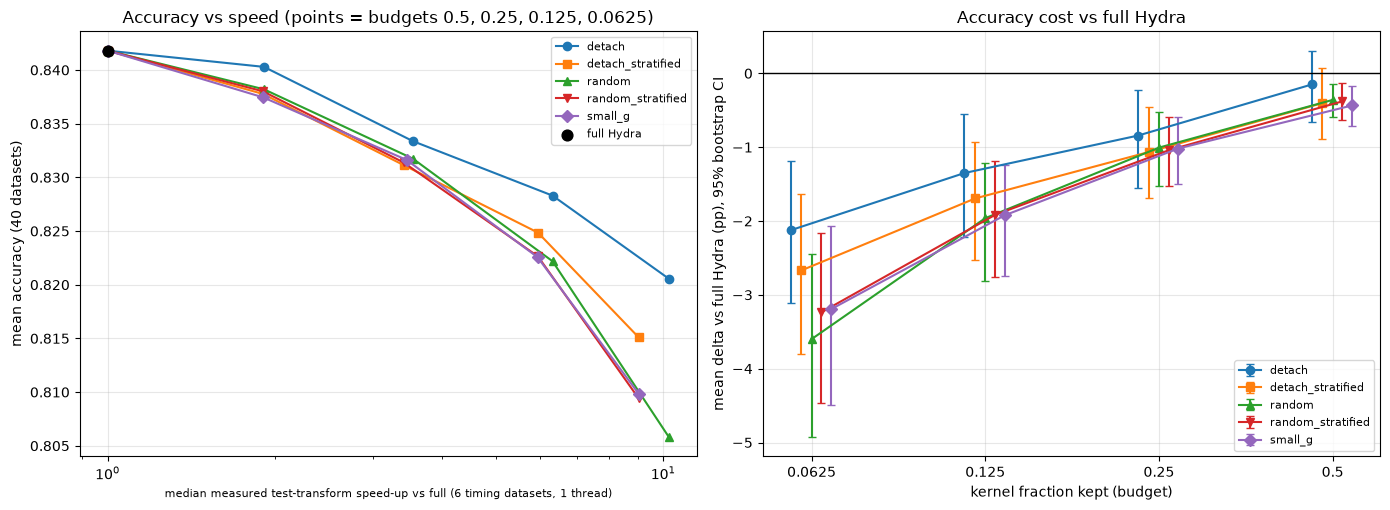

In [20]:
# ---- 6.4 Accuracy vs measured speed-up ----
if len(timing):
    sp = timing.groupby(["method", "budget"])["speedup"].median()
    speed_of = {("detach", b): sp.get(("detach", b), np.nan) for b in BUDGETS}
    speed_of.update({("detach_stratified", b): sp.get(("detach_stratified", b), np.nan) for b in BUDGETS})
    speed_of.update({("small_g", b): sp.get(("small_g", b), np.nan) for b in BUDGETS})
    # random / random_stratified are not timed separately: same kernel count and structure as
    # detach / detach_stratified respectively, so they reuse those speed-ups
    speed_of.update({("random", b): speed_of[("detach", b)] for b in BUDGETS})
    speed_of.update({("random_stratified", b): speed_of[("detach_stratified", b)] for b in BUDGETS})
    x_label = f"median measured test-transform speed-up vs full ({timing['dataset'].nunique()} timing datasets, 1 thread)"
else:
    speed_of = {(m, b): 1 / b for m in METHODS for b in BUDGETS}
    x_label = "1 / kernel fraction (no timing data)"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))
markers = dict(zip(METHODS, ["o", "s", "^", "v", "D"]))
for m in METHODS:
    xs = [1.0] + [speed_of[(m, b)] for b in BUDGETS]
    ys = [FULL.mean()] + [acc_of(m, b).mean() for b in BUDGETS]
    ax1.plot(xs, ys, marker=markers[m], label=m)
ax1.scatter([1.0], [FULL.mean()], color="black", zorder=5, s=60, label="full Hydra")
ax1.set_xscale("log"); ax1.set_xlabel(x_label, fontsize=8); ax1.set_ylabel(f"mean accuracy ({len(DS_USED)} datasets)")
ax1.set_title("Accuracy vs speed (points = budgets 0.5, 0.25, 0.125, 0.0625)")
ax1.grid(alpha=0.3); ax1.legend(fontsize=8)

for j, m in enumerate(METHODS):
    st = [compare(acc_of(m, b), FULL) for b in BUDGETS]
    xs = np.array(BUDGETS) * (1 + 0.04 * (j - 2))
    ax2.errorbar(xs, [s["mean_pp"] for s in st],
                 yerr=[[s["mean_pp"] - s["ci_lo"] for s in st], [s["ci_hi"] - s["mean_pp"] for s in st]],
                 marker=markers[m], capsize=3, label=m)
ax2.axhline(0, color="black", lw=1)
ax2.set_xscale("log"); ax2.set_xticks(BUDGETS, [str(b) for b in BUDGETS])
ax2.xaxis.set_minor_formatter(plt.NullFormatter()); ax2.minorticks_off()
ax2.set_xlabel("kernel fraction kept (budget)"); ax2.set_ylabel("mean delta vs full Hydra (pp), 95% bootstrap CI")
ax2.set_title("Accuracy cost vs full Hydra"); ax2.grid(alpha=0.3); ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}accuracy_vs_speed.png", dpi=150, bbox_inches="tight")
plt.show()

budget 0.25: mean ranks (1 = best)


,full,detach,small_g,detach_stratified,random_stratified,random
mean rank,2.06,3.21,3.7,3.8,3.98,4.25


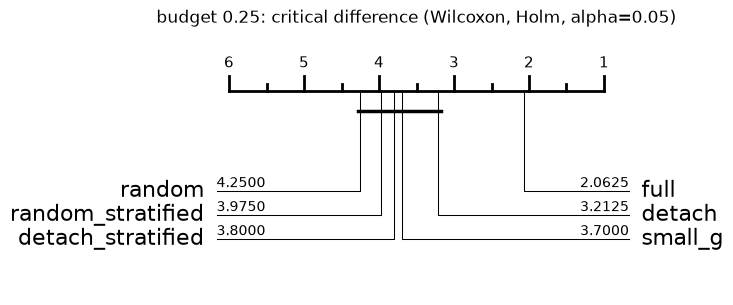

budget 0.125: mean ranks (1 = best)


,full,detach,detach_stratified,random_stratified,small_g,random
mean rank,1.82,3.19,3.51,4.03,4.2,4.25


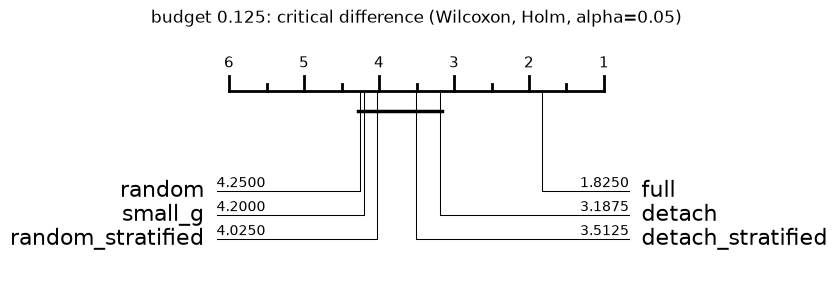

In [21]:
# ---- 6.5 Critical-difference diagrams at budgets 0.25 and 0.125 (6 methods incl. full) ----
cd_ranks = {}
for b in [0.25, 0.125]:
    labels = ["full"] + METHODS
    scores = np.column_stack([FULL.to_numpy()] + [acc_of(m, b).to_numpy() for m in METHODS])
    ranks = pd.DataFrame(scores, columns=labels, index=DS_USED).rank(axis=1, ascending=False).mean()
    cd_ranks[b] = ranks.sort_values()
    print(f"budget {b}: mean ranks (1 = best)"); display(cd_ranks[b].round(2).to_frame("mean rank").T)
    try:
        from aeon.visualisation import plot_critical_difference
        fig, ax = plot_critical_difference(scores, labels, test="wilcoxon", correction="holm", alpha=0.05)
        ax.set_title(f"budget {b}: critical difference (Wilcoxon, Holm, alpha=0.05)")
        fig.savefig(FIG_DIR / f"{FIG_PREFIX}cd_budget_{b}.png", dpi=150, bbox_inches="tight")
        plt.show()
    except Exception as exc:
        print(f"  CD diagram not drawn ({type(exc).__name__}: {exc}); mean ranks above are the fallback")

detach: keep rate by relative dilation, relative to uniform (1.0 = small_g / stratified):


dil_bin,short,mid,long
budget,,,
0.0625,0.69,1.04,1.33
0.1250,0.75,1.02,1.28
0.2500,0.82,1.00,1.22
0.5000,0.87,1.02,1.15


detach: share of kept groups on diff(X) (0.5 = uniform):


,mean,min,max
budget,,,
0.0625,0.364,0.000,0.825
0.1250,0.397,0.025,0.738
0.2500,0.446,0.041,0.728
0.5000,0.483,0.118,0.659


Block coverage (fraction of (dilation, input) blocks with >= 1 kept group):


budget,0.0625,0.1250,0.2500,0.5000,1.0000
method,,,,,
detach,0.720,0.881,0.961,0.997,NaN
detach_stratified,1.000,1.000,1.000,1.000,NaN
full,NaN,NaN,NaN,NaN,1.0
full_author_grid,NaN,NaN,NaN,NaN,1.0
random,0.884,0.989,1.000,1.000,NaN
random_stratified,1.000,1.000,1.000,1.000,NaN
small_g,1.000,1.000,1.000,1.000,NaN


Consistency of per-block kept counts across resamples (weighted Jaccard; random = chance baseline):


method,detach,random
budget,,
0.0625,0.606,0.477
0.1250,0.676,0.600
0.2500,0.748,0.724
0.5000,0.842,0.828


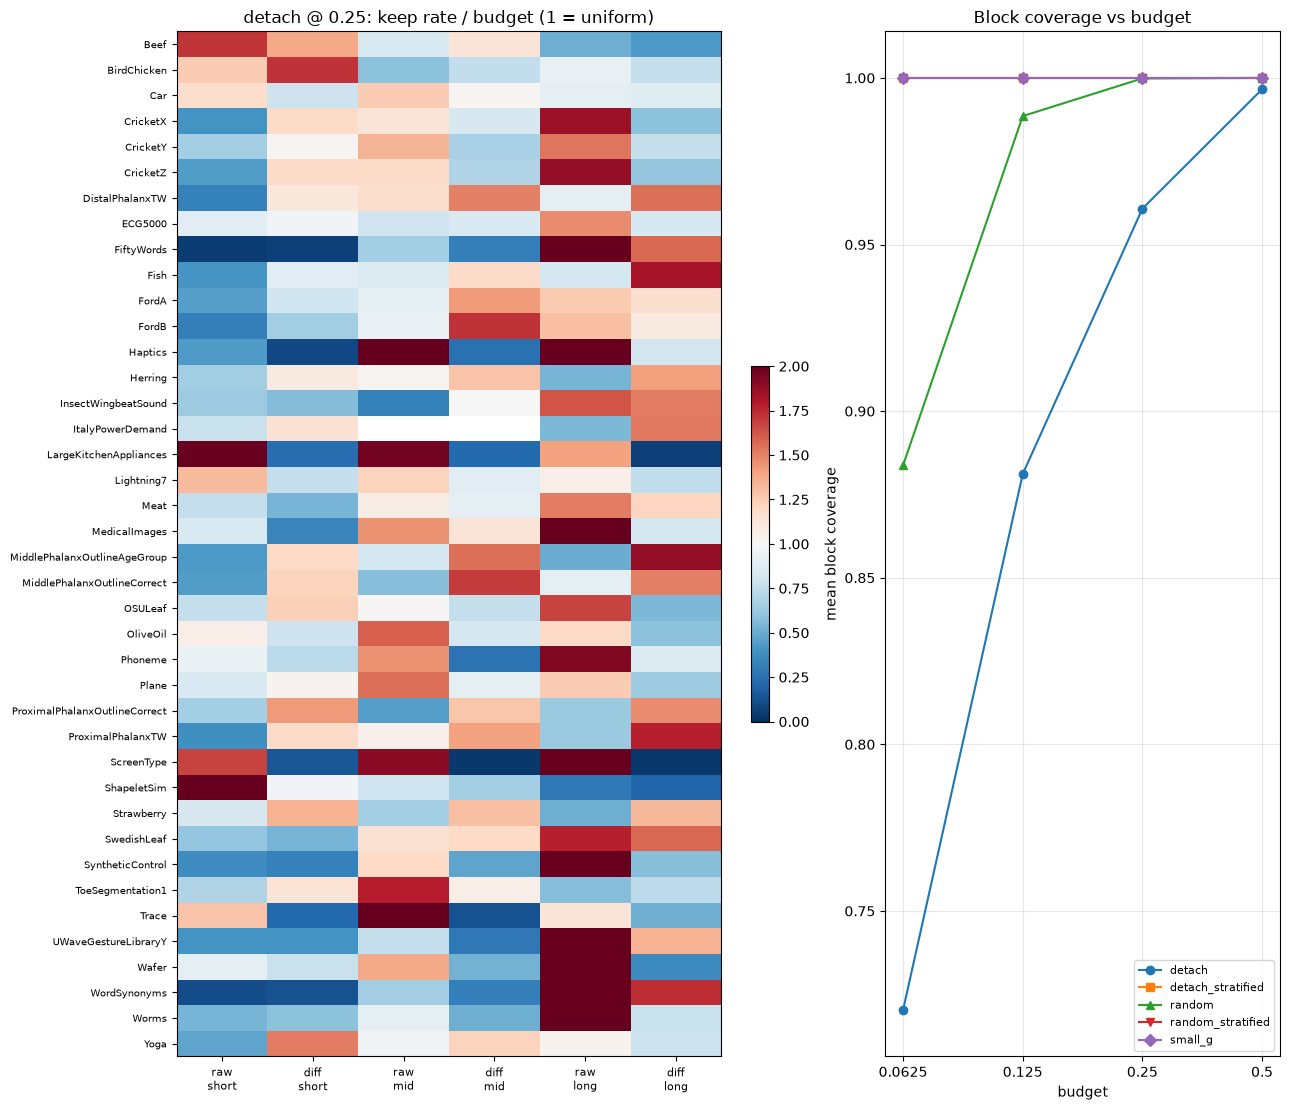

In [22]:
# ---- 6.6 Kept-groups analysis ----
kd = kept_df[kept_df["dataset"].isin(DS_USED)].copy()
nd = kd.groupby("dataset")["dilation_index"].transform("max") + 1
kd["rel_dilation"] = np.where(nd > 1, kd["dilation_index"] / (nd - 1).clip(lower=1), 0.0)
kd["dil_bin"] = pd.cut(kd["rel_dilation"], [-0.01, 1 / 3, 2 / 3, 1.01], labels=["short", "mid", "long"])

det_k = kd[kd["method"] == "detach"]
# keep rate per relative-dilation bin, relative to the budget (1.0 = uniform, as in small_g)
rate = (det_k.groupby(["dataset", "resample", "budget", "dil_bin"], observed=True)["kept"].mean()
        .groupby(["dataset", "budget", "dil_bin"], observed=True).mean().reset_index())
rate["rel_rate"] = rate["kept"] / rate["budget"]
dil_share = rate.groupby(["budget", "dil_bin"], observed=True)["rel_rate"].mean().unstack()
print("detach: keep rate by relative dilation, relative to uniform (1.0 = small_g / stratified):")
display(dil_share.round(2))

diff_share = (det_k[det_k["kept"]].groupby(["dataset", "resample", "budget"])["diff_index"].mean()
              .groupby(["dataset", "budget"]).mean().groupby("budget").agg(["mean", "min", "max"]))
print("detach: share of kept groups on diff(X) (0.5 = uniform):")
display(diff_share.round(3))

cov = runs.groupby(["method", "budget"])["block_coverage"].mean().unstack()
print("Block coverage (fraction of (dilation, input) blocks with >= 1 kept group):")
display(cov.round(3))
min_cov = runs[runs["method"] == "detach"].groupby("budget")["block_coverage"].min()

# consistency across resamples: weighted Jaccard of per-block count vectors (kernel seeds differ per resample)
def wjac(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.minimum(a, b).sum() / np.maximum(a, b).sum()

cons_rows = []
for (ds, b), grp in runs[runs["method"].isin(["detach", "random"])].groupby(["dataset", "budget"]):
    for m in ["detach", "random"]:
        vecs = [json.loads(v) for v in grp[(grp["method"] == m)].sort_values(["resample", "draw"])["block_counts"]]
        if m == "random":
            vecs = vecs[::N_RANDOM_DRAWS]                 # one draw per resample
        sims = [wjac(vecs[i], vecs[j]) for i in range(len(vecs)) for j in range(i + 1, len(vecs))]
        cons_rows.append({"dataset": ds, "budget": b, "method": m, "wjaccard": np.mean(sims) if sims else np.nan})
consistency = pd.DataFrame(cons_rows).groupby(["budget", "method"])["wjaccard"].mean().unstack()
print("Consistency of per-block kept counts across resamples (weighted Jaccard; random = chance baseline):")
display(consistency.round(3))

# per-dataset heatmap at budget 0.25: keep rate per relative-dilation bin and raw/diff
hm = (det_k[det_k["budget"] == 0.25].groupby(["dataset", "resample", "dil_bin", "diff_index"], observed=True)["kept"].mean()
      .groupby(["dataset", "dil_bin", "diff_index"], observed=True).mean().unstack(["diff_index", "dil_bin"]))
hm = hm.reindex(DS_USED)
fig, axes = plt.subplots(1, 2, figsize=(13, max(4, 0.28 * len(DS_USED))), gridspec_kw={"width_ratios": [3, 2]})
im = axes[0].imshow(hm.to_numpy(dtype=float) / 0.25, aspect="auto", cmap="RdBu_r", vmin=0, vmax=2)
axes[0].set_yticks(range(len(hm.index)), hm.index, fontsize=7)
axes[0].set_xticks(range(hm.shape[1]), [f"{'diff' if v else 'raw'}\n{d}" for v, d in hm.columns], fontsize=8)
axes[0].set_title("detach @ 0.25: keep rate / budget (1 = uniform)")
fig.colorbar(im, ax=axes[0], fraction=0.03)
for m, mk in zip(METHODS, markers.values()):
    axes[1].plot(BUDGETS, [cov.loc[m, b] for b in BUDGETS], marker=mk, label=m)
axes[1].set_xscale("log"); axes[1].set_xticks(BUDGETS, [str(b) for b in BUDGETS]); axes[1].minorticks_off()
axes[1].set_xlabel("budget"); axes[1].set_ylabel("mean block coverage"); axes[1].set_title("Block coverage vs budget")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}kept_groups.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# ---- 6.7 Alpha: wide grid vs authors' grid (a reproduction lesson, not an improvement) ----
edge = runs.groupby("method")["alpha_at_edge"].mean().reindex(["full_author_grid", "full"] + METHODS)
print("Share of fits with alpha at a grid edge:")
display(edge.round(3).to_frame("edge rate"))
grid_cmp = compare(FULL, FULL_AUTHOR)
print(f"Full Hydra, wide grid vs authors' grid: {grid_cmp['mean_pp']:+.2f} pp "
      f"(95% CI [{grid_cmp['ci_lo']:+.2f}, {grid_cmp['ci_hi']:+.2f}]), W/D/L {grid_cmp['W']}/{grid_cmp['D']}/{grid_cmp['L']}, "
      f"Wilcoxon p {grid_cmp['p']:.4f}")
path_edge = paths[paths["dataset"].isin(DS_USED)]["alpha_at_edge"].mean()
print(f"Detach path: alpha at the wide-grid edge in {path_edge:.1%} of steps")
alpha_counts = runs[runs["method"].isin(["full", "full_author_grid"])].groupby(["method", "alpha"]).size().unstack(fill_value=0)
display(alpha_counts)

Share of fits with alpha at a grid edge:


,edge rate
method,
full_author_grid,0.740
full,0.165
detach,0.214
detach_stratified,0.195
random,0.082
random_stratified,0.099
small_g,0.085


Full Hydra, wide grid vs authors' grid: -0.18 pp (95% CI [-0.63, +0.25]), W/D/L 11/17/12, Wilcoxon p 0.5090
Detach path: alpha at the wide-grid edge in 20.5% of steps


alpha,0.000001,0.000003,0.000010,0.000032,0.000100,0.000316,0.001000,31.622777,46.415888,100.000000,215.443469,316.227766,1000.000000,3162.277660,10000.000000,31622.776602
method,,,,,,,,,,,,,,,,
full,33,2,5,8,11,1,1,1,0,20,0,40,35,29,7,7
full_author_grid,0,0,0,0,0,0,61,0,6,0,46,0,87,0,0,0


In [24]:
# ---- 6.8 Breakdowns of delta(detach - small_g) ----
bd = meta.set_index("dataset").loc[DS_USED].copy()
bd["train_size"] = pd.cut(bd["n_train"], [0, 100, 500, np.inf], labels=["<=100", "101-500", ">500"])
bd["length"] = pd.cut(bd["series_length"], [0, 200, 500, np.inf], labels=["<=200", "201-500", ">500"])
bd["classes"] = pd.cut(bd["n_classes"], [0, 2, 10, np.inf], labels=["2", "3-10", ">10"])
breakdowns = {}
for b in BUDGETS:
    bd[f"d_{b}"] = (acc_of("detach", b) - acc_of("small_g", b)) * 100
for col in ["train_size", "length", "classes", "type"]:
    t = bd.groupby(col, observed=True)[[f"d_{b}" for b in BUDGETS]].mean()
    t.insert(0, "n_datasets", bd.groupby(col, observed=True).size())
    breakdowns[col] = t
    print(f"delta(detach - small_g) in pp by {col}:"); display(t.round(2))

delta(detach - small_g) in pp by train_size:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
train_size,,,,,
<=100,11,0.69,0.87,1.64,1.61
101-500,22,0.12,-0.10,0.17,0.87
>500,7,0.15,-0.06,0.15,0.85


delta(detach - small_g) in pp by length:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
length,,,,,
<=200,12,-0.49,-1.02,-0.66,-0.40
201-500,19,0.69,1.02,1.60,2.13
>500,9,0.46,-0.02,0.05,0.80


delta(detach - small_g) in pp by classes:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
classes,,,,,
2,12,0.52,0.13,0.73,1.18
3-10,20,-0.04,-0.32,-0.27,-0.18
>10,8,0.75,1.48,2.46,4.04


delta(detach - small_g) in pp by type:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
type,,,,,
Device,2,-0.46,-1.40,-1.72,-0.62
ECG,1,0.17,0.07,0.34,0.38
Image,14,0.08,-0.47,0.34,0.96
Motion,7,0.65,0.36,0.61,1.80
Sensor,10,0.28,0.66,0.67,0.79
Simulated,2,1.49,1.98,2.93,3.53
Spectro,4,0.18,0.80,1.11,0.68


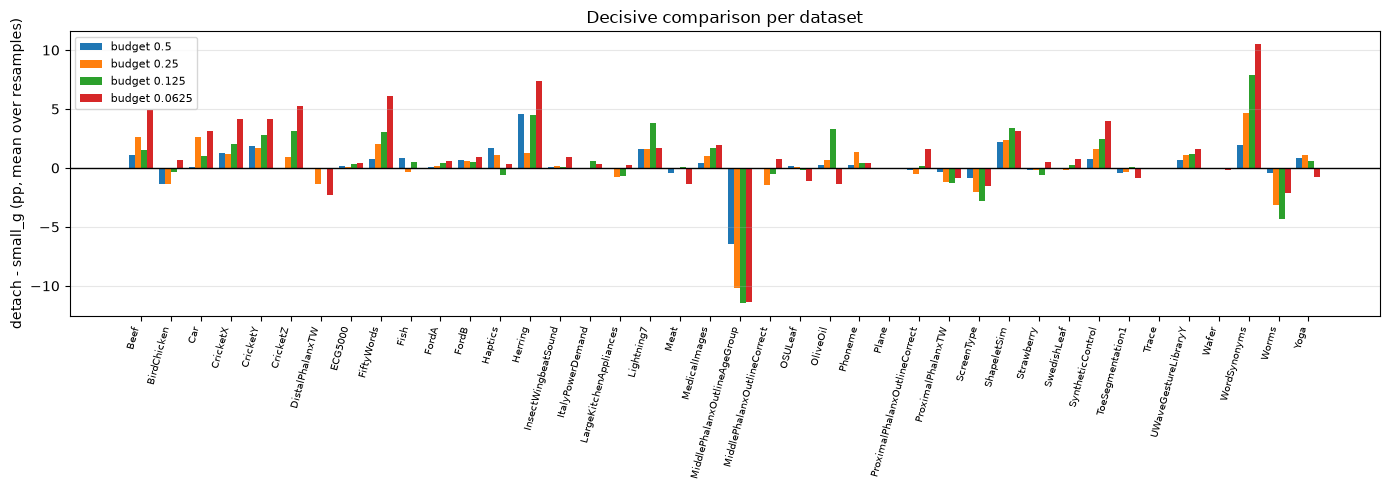

In [25]:
# ---- figure: per-dataset decisive delta at each budget ----
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(DS_USED)); w = 0.8 / len(BUDGETS)
for i, b in enumerate(BUDGETS):
    ax.bar(x + (i - 1.5) * w, (acc_of("detach", b) - acc_of("small_g", b)).to_numpy() * 100, width=w, label=f"budget {b}")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x, DS_USED, rotation=75, ha="right", fontsize=7)
ax.set_ylabel("detach - small_g (pp, mean over resamples)")
ax.set_title("Decisive comparison per dataset")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}per_dataset_delta.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Verdict

The next cell **computes the verdict from the saved numbers**. It shows the verdict below as Markdown, and the cell after it prints the full report in the notebook output (no file is written).

**SUCCESS rule.** At some budget ≤ 0.25, `detach` or `detach_stratified` beats `small_g` with all three of:
- a mean gain of **≥ 0.5 pp**
- **wins ≥ 2 × losses**
- **Holm-corrected Wilcoxon p < 0.05**

Otherwise the verdict is **FAILURE**, written up as an understanding result.

In [26]:
def md_table(df, floatfmt=4):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join([str(df.index.name or "")] + cols) + " |",
             "|" + "---|" * (len(cols) + 1)]
    for idx, row in df.iterrows():
        vals = []
        for v in row:
            if isinstance(v, (float, np.floating)):
                vals.append("" if np.isnan(v) else f"{v:.{floatfmt}f}")
            else:
                vals.append(str(v))
        lines.append("| " + " | ".join([str(idx)] + vals) + " |")
    return "\n".join(lines)


def fam_md(df):
    t = df.copy()
    t = t.set_index(t["comparison"] + " @ " + t["budget"].astype(str))
    t.index.name = "comparison @ budget"
    t = t[["mean_pp", "95% CI (pp)", "median_pp", "W/D/L", "p", "p_holm"]].copy()
    t["mean_pp"] = t["mean_pp"].map(lambda v: f"{v:+.2f}")
    t["median_pp"] = t["median_pp"].map(lambda v: f"{v:+.2f}")
    return md_table(t, floatfmt=4)


def stat_line(df, label, b):
    r_ = df[(df["comparison"] == label) & (df["budget"] == b)].iloc[0]
    return (f"{r_['mean_pp']:+.2f} pp (95% CI [{r_['ci_lo']:+.2f}, {r_['ci_hi']:+.2f}]), W/D/L {r_['W/D/L']}, "
            f"Holm p = {r_['p_holm']:.4f}")


# ---- success rule ----
success = []
for _, r_ in decisive.iterrows():
    if r_["budget"] <= 0.25 and r_["mean_pp"] >= 0.5 and r_["W"] >= 2 * r_["L"] and r_["p_holm"] < 0.05:
        success.append(r_)
SUCCESS = len(success) > 0
speed_txt = lambda m, b: (f"{speed_of[(m, b)]:.2f}x" if np.isfinite(speed_of.get((m, b), np.nan)) else "n/a")

L_ = []
L_.append(f"## Verdict: **{'SUCCESS' if SUCCESS else 'FAILURE'}**\n")
if SUCCESS:
    for r_ in success:
        m = r_["comparison"].split(" - ")[0]
        b = r_["budget"]
        L_.append(f"- **{m}** beats `small_g` at budget **{b}**: {stat_line(decisive, r_['comparison'], b)}. "
                  f"Median measured test-transform speed-up there: **{speed_txt(m, b)}**; accuracy vs full Hydra: "
                  f"**{(acc_of(m, b) - FULL).mean() * 100:+.2f} pp**.")
    L_.append("\nImportance-ranked group pruning is a real improvement over simply using a smaller Hydra at these budgets.")
else:
    L_.append("**Importance pruning ≈ a smaller Hydra; even coverage across dilations and inputs matters more than the ranking.**\n")
    L_.append("No budget ≤ 0.25 meets the success rule (≥ +0.5 pp mean, wins ≥ 2× losses, Holm p < 0.05). Decisive comparison:")
    for b in BUDGETS:
        L_.append(f"- budget {b}: detach − small_g {stat_line(decisive, 'detach - small_g', b)}; "
                  f"detach_stratified − small_g {stat_line(decisive, 'detach_stratified - small_g', b)}")
L_.append("\n**Mechanism comparisons (what was and was not observed):**")
for lab in mechanism["comparison"].unique():
    parts = []
    for b in BUDGETS:
        r_ = mechanism[(mechanism["comparison"] == lab) & (mechanism["budget"] == b)].iloc[0]
        sig = "significant" if r_["p_holm"] < 0.05 else "not significant"
        parts.append(f"{b}: {r_['mean_pp']:+.2f} pp ({r_['W/D/L']}, {sig})")
    L_.append(f"- {lab}: " + "; ".join(parts))
L_.append(f"\n**Kept groups:** at budget 0.0625 global detach keeps groups in "
          f"{cov.loc['detach', 0.0625]:.0%} of blocks on average (minimum {min_cov.loc[0.0625]:.0%}), vs 100% for "
          f"small_g / stratified methods. Keep rate by relative dilation at 0.25 (1 = uniform): "
          + ", ".join(f"{c} {dil_share.loc[0.25, c]:.2f}" for c in dil_share.columns)
          + f"; share on diff(X) at 0.25: {diff_share.loc[0.25, 'mean']:.2f}.")
L_.append(f"\n**Alpha (reproduction lesson):** full Hydra with the wide grid vs the authors' grid: "
          f"{grid_cmp['mean_pp']:+.2f} pp (W/D/L {grid_cmp['W']}/{grid_cmp['D']}/{grid_cmp['L']}); edge rate "
          f"{edge.loc['full_author_grid']:.0%} (authors' grid) vs {edge.loc['full']:.0%} (wide grid).")
L_.append("\n**Caveats:** default split + 4 stratified resamples (not 30); the 40 development datasets were also used "
          "by the authors for tuning; timing on one machine (one thread, 6 datasets); 10% elimination step; "
          "dataset list taken from the team's extraction of the ROCKET appendix (not re-verified here)"
          + ("; **QUICK_RUN smoke test only - not a result**" if QUICK_RUN else "") + ".")
VERDICT_MD = "\n".join(L_)
display(Markdown(VERDICT_MD))

## Verdict: **FAILURE**

**Importance pruning ≈ a smaller Hydra; even coverage across dilations and inputs matters more than the ranking.**

No budget ≤ 0.25 meets the success rule (≥ +0.5 pp mean, wins ≥ 2× losses, Holm p < 0.05). Decisive comparison:
- budget 0.5: detach − small_g +0.28 pp (95% CI [-0.19, +0.72]), W/D/L 22/6/12, Holm p = 0.0895; detach_stratified − small_g +0.03 pp (95% CI [-0.43, +0.46]), W/D/L 20/4/16, Holm p = 1.0000
- budget 0.25: detach − small_g +0.18 pp (95% CI [-0.55, +0.78]), W/D/L 22/5/13, Holm p = 0.1410; detach_stratified − small_g -0.05 pp (95% CI [-0.62, +0.43]), W/D/L 16/8/16, Holm p = 1.0000
- budget 0.125: detach − small_g +0.57 pp (95% CI [-0.35, +1.40]), W/D/L 26/2/12, Holm p = 0.0895; detach_stratified − small_g +0.23 pp (95% CI [-0.38, +0.70]), W/D/L 26/3/11, Holm p = 0.0605
- budget 0.0625: detach − small_g +1.07 pp (95% CI [+0.01, +2.08]), W/D/L 26/3/11, Holm p = 0.0895; detach_stratified − small_g +0.53 pp (95% CI [-0.02, +1.10]), W/D/L 26/4/10, Holm p = 0.0810

**Mechanism comparisons (what was and was not observed):**
- random_stratified - random (even coverage): 0.5: -0.02 pp (16/9/15, not significant); 0.25: -0.04 pp (20/7/13, not significant); 0.125: +0.04 pp (18/8/14, not significant); 0.0625: +0.36 pp (24/7/9, significant)
- small_g - random_stratified (fresh kernels): 0.5: -0.06 pp (14/8/18, not significant); 0.25: +0.02 pp (17/9/14, not significant); 0.125: -0.01 pp (17/7/16, not significant); 0.0625: +0.04 pp (14/10/16, not significant)
- detach - random (ranking): 0.5: +0.21 pp (28/4/8, significant); 0.25: +0.16 pp (24/5/11, not significant); 0.125: +0.61 pp (24/4/12, not significant); 0.0625: +1.48 pp (30/1/9, significant)
- detach_stratified - detach (forced coverage): 0.5: -0.25 pp (9/5/26, significant); 0.25: -0.22 pp (14/4/22, not significant); 0.125: -0.34 pp (14/6/20, not significant); 0.0625: -0.54 pp (15/3/22, not significant)
- detach_stratified - random_stratified (ranking within blocks): 0.5: -0.02 pp (18/6/16, not significant); 0.25: -0.02 pp (18/6/16, not significant); 0.125: +0.22 pp (23/3/14, not significant); 0.0625: +0.57 pp (25/6/9, significant)

**Kept groups:** at budget 0.0625 global detach keeps groups in 72% of blocks on average (minimum 33%), vs 100% for small_g / stratified methods. Keep rate by relative dilation at 0.25 (1 = uniform): short 0.82, mid 1.00, long 1.22; share on diff(X) at 0.25: 0.45.

**Alpha (reproduction lesson):** full Hydra with the wide grid vs the authors' grid: -0.18 pp (W/D/L 11/17/12); edge rate 74% (authors' grid) vs 16% (wide grid).

**Caveats:** default split + 4 stratified resamples (not 30); the 40 development datasets were also used by the authors for tuning; timing on one machine (one thread, 6 datasets); 10% elimination step; dataset list taken from the team's extraction of the ROCKET appendix (not re-verified here).

In [27]:
# ---- full report: printed in the notebook output only (no file is written) ----
R = []
R.append("# Detach-Hydra Decisive Experiment: Findings\n")
if QUICK_RUN:
    R.append("> **QUICK_RUN smoke test (3 datasets x 2 resamples). These numbers are NOT results.**\n")
R.append(f"**Notebook:** `02_detach_hydra/notebooks/02_development_run.ipynb`  \n**Datasets used:** {len(DS_USED)} "
         f"(excluded: {DS_EXCLUDED or 'none'}) x {len(RESAMPLES)} splits  \n"
         f"**Compute:** {TOTAL_PAIR_HOURS:.2f} h of pair runs on {N_THREADS} threads  \n"
         f"**Outputs:** `{RUNS_CSV.name}`, `{PATHS_CSV.name}`, `{KEPT_CSV.name}`, `{TIMING_CSV.name}`, `{FAIL_CSV.name}`; "
         f"figures `02_detach_hydra/results/figures/{FIG_PREFIX}*.png`\n")
R.append("## Question\n\nAt matched kernel budgets, does importance-ranked group pruning (Detach-Hydra) beat simply "
         "using a smaller Hydra (`small_g`)?\n")
R.append("## Setup\n")
R.append("- **Models.** Full Hydra (k=8, g=64, seed = resample id). Budgets 0.5/0.25/0.125/0.0625 of groups, matched "
         "by `small_g` with g' = 32/16/8/4 (16/8/4/2 groups per (dilation, input) block). The total group counts are identical.")
R.append("- **Classifier.** Every model uses `SparseScaler` (train only) and `RidgeClassifierCV(logspace(-6, 6, 25))`. "
         "The full model is also fitted with the authors' `logspace(-3, 3, 10)` for reference.")
R.append("- **Detach path.** Train only, with alpha re-selected at every step. It removes 10% per step, clamped to land exactly on "
         "each budget. The score is the L2 norm of `atleast_2d(coef_)` per group.")
R.append("- **detach_stratified.** The top 32·b groups per block under the importance ordering at the budget step. Active groups "
         "rank first by score, then eliminated groups latest-first, with ties broken by last score.")
R.append("- **Controls.** `random` (3 draws, global), `random_stratified` (3 draws, 32·b per block), `small_g` "
         "(3 kernel seeds). Accuracy for pruned models comes from column-subsetting the full features, which is "
         "bit-exact (checked).\n")
R.append("## Checks\n")
R += [f"- **{res}**: {name}" for name, res in CHECKS]
R.append("")
R.append("## Main table: mean accuracy over datasets\n")
mt = main_table.copy(); mt.index.name = "budget"
R.append(md_table(mt.round(4)))
R.append(f"\nFull Hydra: wide grid {FULL.mean():.4f}, authors' grid {FULL_AUTHOR.mean():.4f}.\n")
R.append("**Mean Δ vs full Hydra (pp):**\n")
dfm = delta_full.copy(); dfm.index.name = "budget"
R.append(md_table(dfm.round(2), floatfmt=2) + "\n")
R.append("## Decisive comparison\n")
R.append(fam_md(decisive) + "\n")
R.append("## Mechanism comparisons\n")
R.append(fam_md(mechanism) + "\n")
if len(timing):
    R.append("## Timing (1 thread, median over the timing datasets)\n")
    tt = timing.pivot_table(index=["method", "budget"], values=["speedup", "latency_ms", "kernel_frac"], aggfunc="median")
    tt.index = [f"{m} @ {b}" for m, b in tt.index]; tt.index.name = "method @ budget"
    R.append(md_table(tt.round(3), floatfmt=3) + "\n")
R.append("## Critical-difference ranks (mean rank, 1 = best)\n")
for b, rk in cd_ranks.items():
    R.append(f"- budget {b}: " + ", ".join(f"{m} {v:.2f}" for m, v in rk.items()))
R.append("")
R.append("## Kept groups\n")
R.append("**Keep rate by relative dilation, relative to uniform (detach):**\n")
ds_ = dil_share.copy(); ds_.columns = [str(c) for c in ds_.columns]; ds_.index.name = "budget"
R.append(md_table(ds_.round(2), floatfmt=2) + "\n")
R.append("**Share of kept groups on diff(X) (detach; 0.5 = uniform):**\n")
dsh = diff_share.copy(); dsh.index.name = "budget"
R.append(md_table(dsh.round(3), floatfmt=3) + "\n")
R.append("**Block coverage (fraction of blocks with ≥1 kept group):**\n")
cv_ = cov.copy(); cv_.columns = [str(c) for c in cv_.columns]; cv_.index.name = "method"
R.append(md_table(cv_.round(3), floatfmt=3) + "\n")
R.append("**Consistency across resamples (weighted Jaccard of per-block counts; random = chance):**\n")
cs_ = consistency.copy(); cs_.index.name = "budget"
R.append(md_table(cs_.round(3), floatfmt=3) + "\n")
R.append("## Alpha (reproduction lesson)\n")
R.append(f"- Edge rate: authors' grid {edge.loc['full_author_grid']:.1%}, wide grid (full) {edge.loc['full']:.1%}; "
         f"detach path steps at the wide-grid edge: {path_edge:.1%}.")
R.append(f"- Full Hydra, wide vs authors' grid: {grid_cmp['mean_pp']:+.2f} pp (95% CI [{grid_cmp['ci_lo']:+.2f}, "
         f"{grid_cmp['ci_hi']:+.2f}]), W/D/L {grid_cmp['W']}/{grid_cmp['D']}/{grid_cmp['L']}, p = {grid_cmp['p']:.4f}.\n")
R.append("## Breakdowns of Δ(detach − small_g), pp\n")
for col, t in breakdowns.items():
    t2 = t.copy(); t2.index = t2.index.astype(str); t2.index.name = col
    R.append(f"**By {col}:**\n\n" + md_table(t2.round(2), floatfmt=2) + "\n")
R.append("## Figures\n")
R.append(f"- `{FIG_PREFIX}accuracy_vs_speed.png`: left, mean accuracy against median measured speed-up "
         "(random and random_stratified reuse the speed-ups of detach and detach_stratified, which have the same kernel structure); "
         "right, mean Δ vs full with bootstrap CIs at each budget.")
R.append(f"- `{FIG_PREFIX}cd_budget_0.25.png`, `{FIG_PREFIX}cd_budget_0.125.png`: critical-difference diagrams "
         "(Wilcoxon + Holm, α = 0.05), drawn if aeon could plot them. The mean ranks are listed above.")
R.append(f"- `{FIG_PREFIX}kept_groups.png`: left, detach keep rate per (input, relative dilation) at budget 0.25 per "
         "dataset (1 = uniform); right, block coverage vs budget per method.")
R.append(f"- `{FIG_PREFIX}per_dataset_delta.png`: detach − small_g per dataset at each budget.\n")
R.append(VERDICT_MD.replace("## Verdict", "## Verdict"))
print("\n".join(R))

wrote /Users/shreed/PROJECTS/Hydra_1/results/Shreed/DETACH_HYDRA_DECISIVE_FINDINGS.md
